# Taller — Análisis Predictivo de Datos
### Business Analytics


**Programa** | Especialización en Analítica y Ciencia de Datos, Universidad de Cundinamarca


Jeison Fabian Malagon Benavides


## Preparación del entorno

Se importan **pandas** y **numpy** para manipular datos, **matplotlib** y **seaborn** para graficar, y de **scikit-learn** las herramientas para construir, entrenar y evaluar modelos predictivos: partición train/test, dos algoritmos de regresión (`LinearRegression` y `RandomForestRegressor`) y las métricas de error. Se fija una semilla aleatoria (`RANDOM_STATE`) para que los resultados sean reproducibles.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10})
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", None)

AZUL, NARANJA, GRIS, ROJO, VERDE = "#2E74B5", "#E8A33D", "#7F7F7F", "#C0504D", "#4C9A6A"
RANDOM_STATE = 42

def millones(x, pos=None):
    # Formatea un valor en pesos como millones: 1500000 -> '$2 M'
    return f"${x/1e6:,.1f} M" if abs(x) < 1e6 else f"${x/1e6:,.0f} M"

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Carga y exploración de los datos

Paso 1. Se carga el mismo archivo `ventas.csv` usado en el taller de Obtención de datos y en la práctica de Análisis Descriptivo, para que las predicciones se construyan sobre la misma fuente de información.

In [15]:
RUTA_ARCHIVO = "ventas.csv"

if not os.path.exists(RUTA_ARCHIVO):
    try:
        from google.colab import files
        print("Archivo no encontrado en el repositorio. Sube 'ventas.csv' manualmente:")
        subido = files.upload()
        RUTA_ARCHIVO = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError("No se encontró 'ventas.csv'. Colócalo en la misma carpeta que este notebook.")

df_raw = pd.read_csv(RUTA_ARCHIVO)
print(f"Datos cargados: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas.")
df_raw.head(5)

Datos cargados: 426 filas x 6 columnas.


,Fecha,Region,Producto,Vendedor,Unidades,PrecioUnitario
0,2026-06-01,Bogotá,Webcam,Luis Peña,3.00,95000
1,2026-01-15,Barranquilla,Webcam,Luis Peña,2.00,115000
2,2025-06-23,Cali,Mouse,Diana Gómez,3.00,60000
3,2026-04-16,Barranquilla,Monitor,Ana Torres,3.00,660000
4,2025-10-24,Cali,Webcam,Ana Torres,8.00,85000


**Paso 2. Exploración inicial.** El diagnóstico detallado (nulos, duplicados, precios negativos, texto inconsistente)

In [3]:
print(f"Filas duplicadas exactas: {df_raw.duplicated().sum()}")
print(f"Valores nulos en 'Unidades': {df_raw['Unidades'].isnull().sum()}")
print(f"Precios unitarios negativos: {(df_raw['PrecioUnitario'] < 0).sum()}")
print(f"Categorías de 'Region' antes de limpiar: {sorted(df_raw['Region'].unique())}")

Filas duplicadas exactas: 6
Valores nulos en 'Unidades': 6
Precios unitarios negativos: 4
Categorías de 'Region' antes de limpiar: ['  barranquilla  ', '  bucaramanga  ', '  medellín  ', '  pereira  ', 'BARRANQUILLA', 'BOGOTÁ', 'BUCARAMANGA', 'Barranquilla', 'Bogotá', 'Bucaramanga', 'CALI', 'Cali', 'MEDELLÍN', 'Medellín', 'PEREIRA', 'Pereira']


## Preparación y limpieza de los datos

Se aplican, en el mismo orden que en los talleres anteriores, las transformaciones necesarias para que el conjunto sea confiable:

- Eliminar duplicados exactos.
- Estandarizar texto en `Region`, `Vendedor` y `Producto` (mayúsculas/minúsculas y espacios).
- Convertir `Fecha` a tipo fecha y derivar `Anio`, `Mes`, `Trimestre` y `Periodo`.
- Eliminar filas sin `Unidades` (no se puede calcular el ingreso sin cantidad).
- Corregir precios negativos (error de signo) con valor absoluto.
- Calcular `VentaTotal = Unidades × PrecioUnitario`, la variable que luego se busca predecir.

In [4]:
df = df_raw.copy()

antes = len(df)
df = df.drop_duplicates()
print(f"Duplicados eliminados: {antes - len(df)}")

for col in ["Region", "Vendedor", "Producto"]:
    df[col] = df[col].astype(str).str.strip().str.title()

df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
df["Anio"] = df["Fecha"].dt.year
df["Mes"] = df["Fecha"].dt.month
df["Trimestre"] = df["Fecha"].dt.to_period("Q").astype(str)
df["Periodo"] = df["Fecha"].dt.to_period("M").astype(str)

antes = len(df)
df = df.dropna(subset=["Unidades"])
df["Unidades"] = df["Unidades"].astype(int)
print(f"Filas eliminadas por 'Unidades' nula: {antes - len(df)}")

df["PrecioUnitario"] = df["PrecioUnitario"].abs()
df["VentaTotal"] = df["Unidades"] * df["PrecioUnitario"]

df = df[["Fecha", "Anio", "Mes", "Trimestre", "Periodo", "Region", "Producto", "Vendedor", "Unidades", "PrecioUnitario", "VentaTotal"]]
df = df.sort_values("Fecha").reset_index(drop=True)

print(f"\nLimpieza completada: {df.shape[0]} filas x {df.shape[1]} columnas.")
print(f"Regiones: {sorted(df['Region'].unique())}")
df.head(5)

Duplicados eliminados: 6
Filas eliminadas por 'Unidades' nula: 6

Limpieza completada: 414 filas x 11 columnas.
Regiones: ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Medellín', 'Pereira']


,Fecha,Anio,Mes,Trimestre,Periodo,Region,Producto,Vendedor,Unidades,PrecioUnitario,VentaTotal
0,2025-01-02,2025,1,2025Q1,2025-01,Barranquilla,Mouse,Luis Peña,11,50000,550000
1,2025-01-03,2025,1,2025Q1,2025-01,Barranquilla,Audífonos,Carlos Ruiz,14,160000,2240000
2,2025-01-05,2025,1,2025Q1,2025-01,Bucaramanga,Webcam,Jorge Salas,13,105000,1365000
3,2025-01-08,2025,1,2025Q1,2025-01,Bogotá,Monitor,Sofía Reyes,3,650000,1950000
4,2025-01-09,2025,1,2025Q1,2025-01,Cali,Audífonos,Jorge Salas,4,140000,560000


La limpieza deja **414 transacciones** sin nulos, duplicados ni inconsistencias de texto — el mismo conjunto depurado usado en el Análisis Descriptivo. Sobre este conjunto se construyen los modelos predictivos.

## Selección de variables relevantes (Problema 1)

**Variable objetivo (target):** `VentaTotal`, el ingreso de la transacción.

**Variables predictoras elegidas:** `Producto`, `Region`, `Vendedor`, `Unidades` y `Mes`. Son datos que ya se conocen **en el momento en que se registra el pedido**, antes de que la transacción se cierre del todo.

**Variable deliberadamente excluida:** `PrecioUnitario`. Como `VentaTotal = Unidades × PrecioUnitario`, incluir `PrecioUnitario` como predictora volvería el cálculo trivial (una simple multiplicación) y no un problema de predicción real; además, en la práctica el precio final de una negociación puede no estar cerrado en el momento de registrar el pedido. Excluirlo obliga al modelo a **aprender el patrón de negocio** (qué producto, en qué volumen, tiende a generar qué ingreso) en lugar de repetir una fórmula, que es justamente lo que un modelo predictivo debe aportar.

Las variables categóricas (`Producto`, `Region`, `Vendedor`) se codifican con variables indicadoras (*one-hot encoding*) para que los algoritmos puedan usarlas numéricamente. Los datos se dividen en **80 % entrenamiento / 20 % prueba**, de forma que el modelo se evalúa sobre transacciones que no vio durante el ajuste.

In [5]:
VARIABLES_CATEGORICAS = ["Producto", "Region", "Vendedor"]
VARIABLES_NUMERICAS = ["Unidades", "Mes"]

X = pd.get_dummies(df[VARIABLES_CATEGORICAS + VARIABLES_NUMERICAS], columns=VARIABLES_CATEGORICAS, drop_first=True)
y = df["VentaTotal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Variables predictoras después de codificar: {X.shape[1]}")
print(f"Entrenamiento: {X_train.shape[0]} transacciones  |  Prueba: {X_test.shape[0]} transacciones")

Variables predictoras después de codificar: 18
Entrenamiento: 331 transacciones  |  Prueba: 83 transacciones


## Modelo predictivo 1a: Regresión lineal (línea base)

Se entrena primero una **regresión lineal** como modelo de referencia: asume que cada variable aporta de forma aditiva al ingreso. Es el modelo predictivo básico más simple y sirve de punto de comparación.

In [6]:
def calcular_metricas(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"R2": r2, "MAE": mae, "RMSE": rmse, "MAPE %": mape}

modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
pred_lr = modelo_lr.predict(X_test)

metricas_lr = calcular_metricas(y_test, pred_lr)
print("Regresión lineal — desempeño en el conjunto de prueba:")
for k, v in metricas_lr.items():
    print(f"  {k}: {v:,.2f}" if k != "R2" else f"  {k}: {v:.3f}")

Regresión lineal — desempeño en el conjunto de prueba:
  R2: 0.774
  MAE: 2,125,625.20
  RMSE: 3,639,311.77
  MAPE %: 132.16


**Interpretación.** La regresión lineal explica el 77,4 % de la variación del ingreso (R² = 0,774), con un error promedio absoluto (MAE) de alrededor de $2,13 millones por transacción y un **MAPE de 132 %**: el error porcentual es enorme porque el modelo reparte sus errores por igual entre transacciones de $50.000 (mouse) y de $2.800.000 (laptop), y para las más baratas una sobreestimación de un par de cientos de miles de pesos representa varias veces su valor real. La regresión lineal no capta bien la **interacción entre producto y unidades** (el ingreso no crece igual por unidad adicional según el producto), que es justamente una relación no lineal.

## Modelo predictivo 1b: Random Forest Regressor

Se entrena un **bosque aleatorio de regresión**, un algoritmo basado en múltiples árboles de decisión que sí puede capturar relaciones no lineales y de interacción (por ejemplo, que el efecto de `Unidades` sobre el ingreso depende del `Producto`).

In [7]:
modelo_rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)

metricas_rf = calcular_metricas(y_test, pred_rf)
print("Random Forest — desempeño en el conjunto de prueba:")
for k, v in metricas_rf.items():
    print(f"  {k}: {v:,.2f}" if k != "R2" else f"  {k}: {v:.3f}")

Random Forest — desempeño en el conjunto de prueba:
  R2: 0.999
  MAE: 150,454.42
  RMSE: 216,656.49
  MAPE %: 8.31


**Interpretación.** El Random Forest explica el **99,9 % de la variación del ingreso** (R² = 0,999), con un MAE de apenas ~$150.000 y un MAPE de 8,3 %: una mejora enorme frente a la regresión lineal. La siguiente celda explica **por qué** el salto es tan grande.

In [8]:
variabilidad_precio = df.groupby("Producto")["PrecioUnitario"].agg(Media="mean", DesvEst="std")
variabilidad_precio["Coef. de variación"] = variabilidad_precio["DesvEst"] / variabilidad_precio["Media"]
variabilidad_precio.sort_values("Coef. de variación")

,Media,DesvEst,Coef. de variación
Producto,,,
Laptop,"2,806,949.15","10,546.16",0.00
Monitor,"653,442.62","10,783.51",0.02
Impresora,"484,509.80","10,642.13",0.02
Audífonos,"154,142.86","9,852.96",0.06
Teclado,"125,882.35","10,035.23",0.08
Webcam,"99,923.08","11,608.60",0.12
Mouse,"65,263.16","11,511.68",0.18


## Comparación de modelos

Se reúnen las métricas de ambos modelos y se visualiza el valor predicho frente al valor real en el conjunto de prueba.

In [9]:
comparacion = pd.DataFrame({"Regresión lineal": metricas_lr, "Random Forest": metricas_rf}).T
comparacion

,R2,MAE,RMSE,MAPE %
Regresión lineal,0.77,"2,125,625.20","3,639,311.77",132.16
Random Forest,1.00,"150,454.42","216,656.49",8.31


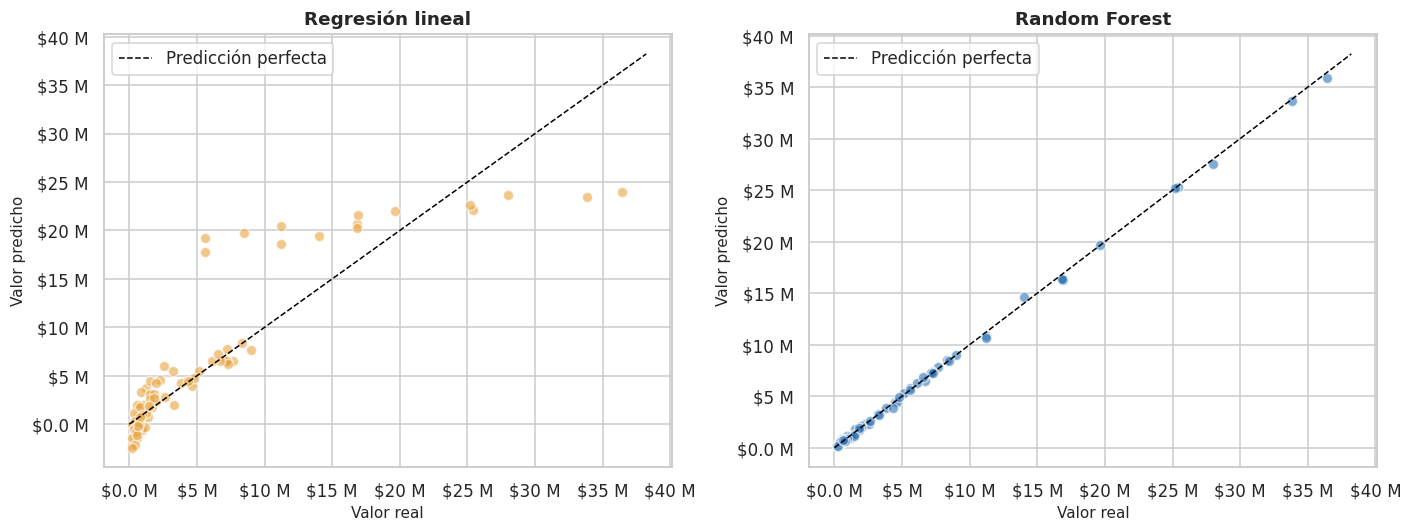

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pred, nombre, color in zip(ejes, [pred_lr, pred_rf], ["Regresión lineal", "Random Forest"], [NARANJA, AZUL]):
    ax.scatter(y_test, pred, alpha=0.6, color=color, edgecolor="white", s=45)
    lim = [0, max(y_test.max(), pred.max()) * 1.05]
    ax.plot(lim, lim, color="black", linestyle="--", linewidth=1, label="Predicción perfecta")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(millones)); ax.yaxis.set_major_formatter(mtick.FuncFormatter(millones))
    ax.set_xlabel("Valor real"); ax.set_ylabel("Valor predicho"); ax.set_title(nombre); ax.legend()

plt.tight_layout(); plt.show()

**Interpretación.** En el panel de la regresión lineal los puntos se dispersan lejos de la diagonal, sobre todo en los valores bajos.

## Importancia de las variables

El Random Forest permite medir cuánto contribuye cada variable a reducir el error de predicción.

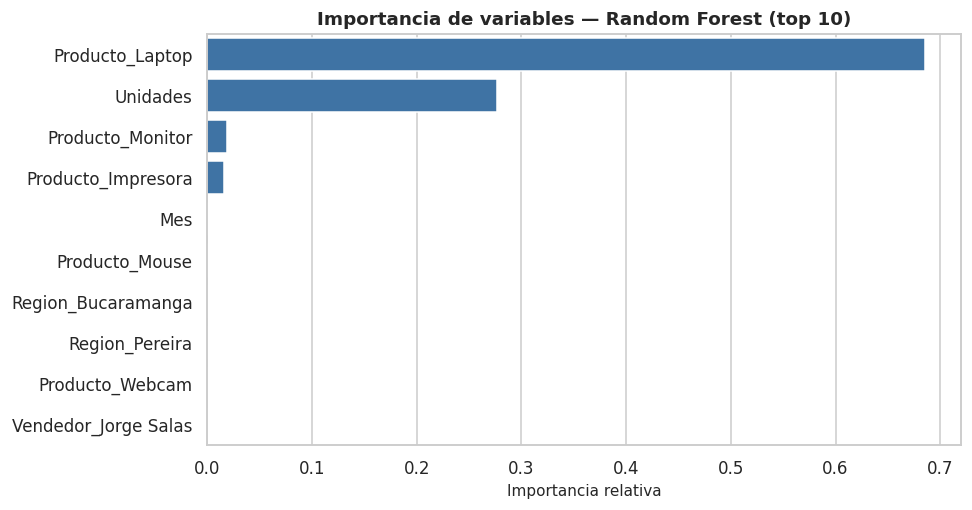

,0
Producto_Laptop,0.69
Unidades,0.28
Producto_Monitor,0.02
Producto_Impresora,0.02
Mes,0.00
Producto_Mouse,0.00
Region_Bucaramanga,0.00
Region_Pereira,0.00
Producto_Webcam,0.00
Vendedor_Jorge Salas,0.00


In [11]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4.8))
sns.barplot(x=importancias.values, y=importancias.index, color=AZUL)
plt.title("Importancia de variables — Random Forest (top 10)")
plt.xlabel("Importancia relativa"); plt.ylabel("")
plt.tight_layout(); plt.show()

importancias

**Interpretación.** `Producto_Laptop` concentra el 68,6 % de la importancia y `Unidades` el 27,7 %; entre ambas suman más del 96 % de la capacidad predictiva del modelo. El resto de categorías de producto, región y vendedor aportan muy poco.

### Revisión de errores (residuales)

Se grafican los residuales (real − predicho) del Random Forest frente al valor predicho, para verificar que el modelo no comete errores sistemáticos.

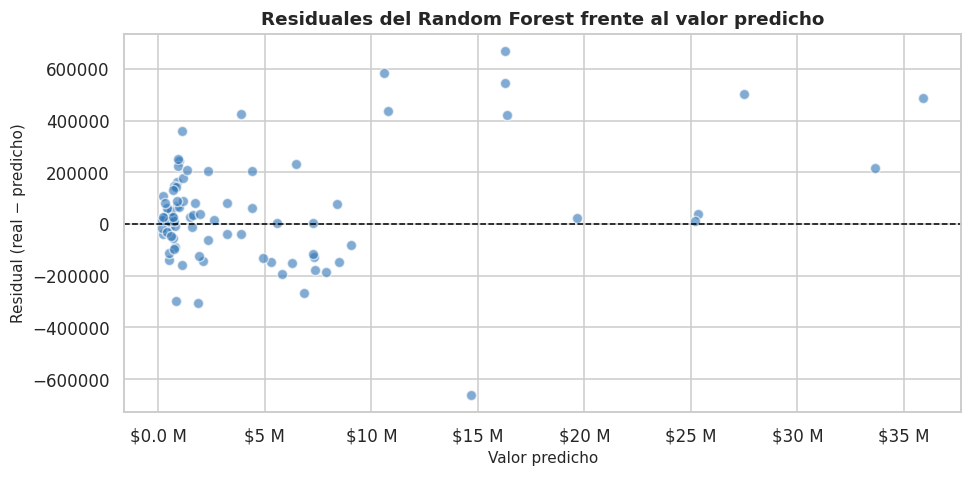

Residual medio: $49,099  |  Desviación de los residuales: $211,020


In [12]:
residuales = y_test.values - pred_rf

plt.figure(figsize=(9, 4.5))
plt.scatter(pred_rf, residuales, alpha=0.6, color=AZUL, edgecolor="white", s=45)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(millones))
plt.title("Residuales del Random Forest frente al valor predicho")
plt.xlabel("Valor predicho"); plt.ylabel("Residual (real − predicho)")
plt.tight_layout(); plt.show()

print(f"Residual medio: ${residuales.mean():,.0f}  |  Desviación de los residuales: ${residuales.std():,.0f}")

**Interpretación.** Los residuales se distribuyen alrededor de cero sin un patrón creciente o curvo evidente: el modelo no subestima ni sobreestima sistemáticamente ningún rango de valores.

## Problema predictivo 2: proyección de ventas futuras

El Análisis Descriptivo mostró una evolución mensual volátil (coeficiente de variación 0,32) y sin una tendencia sostenida clara en 2026. Aun así, se aplica un **modelo predictivo básico de tendencia** —una regresión lineal sobre el tiempo— para proyectar los tres meses siguientes al final de los datos (julio, agosto y septiembre de 2026), y se contrasta con la **media móvil de 3 meses** ya usada en la práctica anterior, como verificación cruzada.

In [13]:
mensual = df.groupby("Periodo")["VentaTotal"].sum().reset_index()
mensual["t"] = range(len(mensual))
mensual["MediaMovil3m"] = mensual["VentaTotal"].rolling(3).mean()

modelo_tendencia = LinearRegression()
modelo_tendencia.fit(mensual[["t"]], mensual["VentaTotal"])

r2_tendencia = modelo_tendencia.score(mensual[["t"]], mensual["VentaTotal"])
pendiente = modelo_tendencia.coef_[0]

periodos_futuros = pd.period_range(
    start=pd.Period(mensual["Periodo"].iloc[-1], freq="M") + 1, periods=3, freq="M"
).astype(str)
t_futuro = pd.DataFrame({"t": range(len(mensual), len(mensual) + 3)})
pronostico = modelo_tendencia.predict(t_futuro)

tabla_pronostico = pd.DataFrame({"Periodo": periodos_futuros, "Ventas proyectadas (tendencia)": pronostico})
print(f"Pendiente de la tendencia mensual: ${pendiente:,.0f} por mes  |  R² del ajuste (dentro de muestra): {r2_tendencia:.3f}")
print(f"Media móvil de 3 meses del último periodo observado ({mensual['Periodo'].iloc[-1]}): ${mensual['MediaMovil3m'].iloc[-1]:,.0f}")
tabla_pronostico

Pendiente de la tendencia mensual: $1,189,190 por mes  |  R² del ajuste (dentro de muestra): 0.034
Media móvil de 3 meses del último periodo observado (2026-06): $109,343,333


,Periodo,Ventas proyectadas (tendencia)
0,2026-07,"117,817,026.14"
1,2026-08,"119,006,216.03"
2,2026-09,"120,195,405.92"


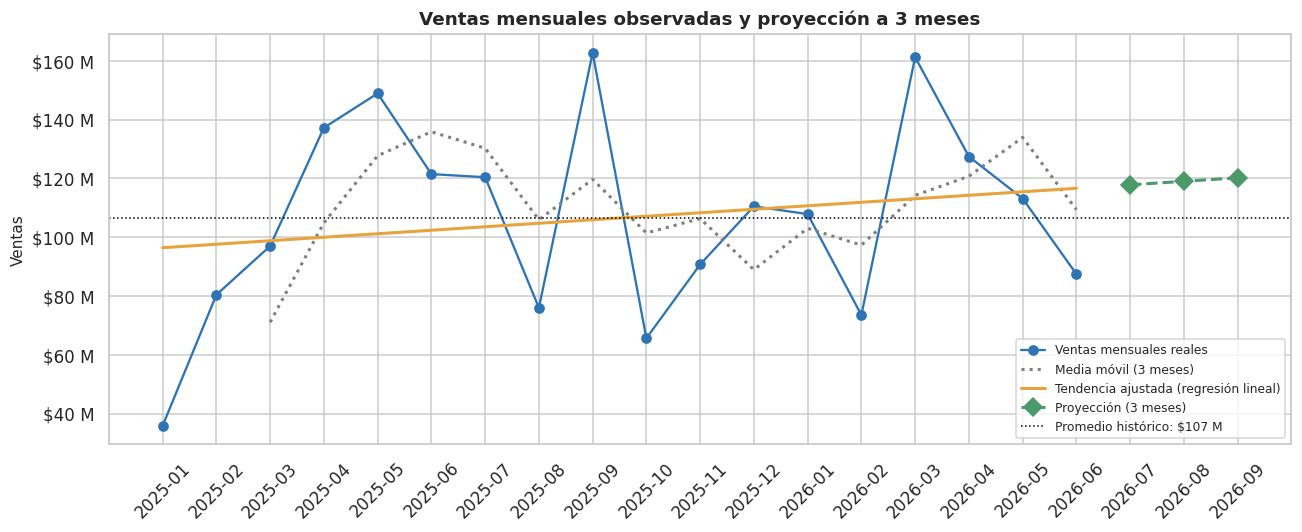

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mensual["Periodo"], mensual["VentaTotal"], marker="o", color=AZUL, label="Ventas mensuales reales")
ax.plot(mensual["Periodo"], mensual["MediaMovil3m"], color=GRIS, linewidth=2, linestyle=":", label="Media móvil (3 meses)")
ax.plot(mensual["Periodo"], modelo_tendencia.predict(mensual[["t"]]), color=NARANJA, linewidth=2, label="Tendencia ajustada (regresión lineal)")
ax.plot(periodos_futuros, pronostico, marker="D", color=VERDE, linestyle="--", linewidth=2, markersize=8, label="Proyección (3 meses)")
ax.axhline(mensual["VentaTotal"].mean(), color="black", linestyle=":", linewidth=1, label=f"Promedio histórico: {millones(mensual['VentaTotal'].mean())}")

ax.yaxis.set_major_formatter(mtick.FuncFormatter(millones))
ax.set_title("Ventas mensuales observadas y proyección a 3 meses")
ax.set_xlabel(""); ax.set_ylabel("Ventas")
plt.xticks(rotation=45); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación.** La tendencia lineal proyecta ventas de **$117,8, $119,0 y $120,2 millones** para julio, agosto y septiembre de 2026 respectivamente, ligeramente por encima del promedio histórico ($106,5 millones) y de la media móvil del último mes observado ($109,3 millones): ambos métodos coinciden en un rango de **$109 a $120 millones** para los próximos meses, sin señales de una caída abrupta.



## Interpretación orientada a la toma de decisiones

- **Estimación por transacción (Problema 1):** con el modelo Random Forest, el equipo comercial puede obtener una **estimación automática del ingreso esperado** apenas se registra un pedido (producto, unidades, región, vendedor y mes), sin esperar a que el precio quede cerrado. Esto sirve para fijar metas realistas por vendedor y para detectar pedidos que se desvían mucho de lo esperado (posible error de captura o una negociación fuera de lo normal).
- **Concentración de valor:** la importancia de variables confirma que **las laptops son el factor que más mueve el ingreso**. Cualquier estrategia de diversificación de producto (ya recomendada en el Análisis Descriptivo) debería monitorearse con este mismo modelo: si la importancia de otros productos empieza a subir, es una señal de que la dependencia de las laptops se está reduciendo.
- **Proyección mensual (Problema 2):** la proyección de **$109 a $120 millones** para el próximo trimestre es útil como referencia de planeación (inventario, metas, flujo de caja), pero la baja capacidad explicativa de la tendencia (R² = 0,034) exige complementarla con el conocimiento del negocio: si se sabe de antemano que hay (o no hay) ventas grandes de laptops programadas para esos meses, esa información pesa más que el modelo estadístico.

## Conclusiones, limitaciones y recomendaciones

**Conclusiones**

1. Es posible predecir el ingreso de una transacción con **alta precisión (R² = 0,999; MAPE = 8,3 %)** usando solo producto, unidades, región, vendedor y mes, sin necesidad de conocer el precio final.
2. La regresión lineal, al ser aditiva, es un modelo predictivo insuficiente para este problema (R² = 0,774; MAPE = 132 %); un algoritmo que capture interacciones (Random Forest) mejora drásticamente el resultado.
3. La variable que más explica el ingreso es, de nuevo, el producto **laptop**, seguida de las unidades vendidas — coherente con el hallazgo central del Análisis Descriptivo.
4. La proyección de ventas mensuales futuras es posible pero **poco precisa** con una simple tendencia lineal, porque el negocio depende de pocas ventas grandes más que de una evolución suave en el tiempo.

**Limitaciones**

- El conjunto tiene 414 transacciones y solo 18 meses de historia: es poco para un modelo de series de tiempo robusto (se necesitarían varios años de datos para capturar estacionalidad real).
- No se probaron otros algoritmos (gradient boosting, redes neuronales) ni se ajustaron hiperparámetros por búsqueda exhaustiva, porque la guía pide un **modelo predictivo básico**; el Random Forest ya usado deja margen de mejora.
- El modelo de Problema 1 asume que el futuro se comporta como el pasado: un producto nuevo o un cambio de precio importante requeriría reentrenar el modelo.

**Recomendaciones**

1. Usar el modelo de Random Forest como apoyo (no reemplazo) de la estimación comercial, revisándolo cada vez que se agreguen nuevas transacciones.
2. Probar, como siguiente paso, un modelo de series de tiempo más especializado (por ejemplo, suavizamiento exponencial o `Prophet`) cuando se acumulen más meses de historia.
3. Monitorear la importancia de variables en el tiempo como indicador de si la dependencia de las laptops está disminuyendo.
4. Repetir la proyección mensual cada vez que cierre un mes, para que la tendencia se actualice con la información más reciente.